# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Куролёнок Карина Юрьевна
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 140

clean = pd.read_parquet("clean_data.parquet")
df_clients = pd.read_parquet("clean_clients.parquet")
campaign = pd.read_csv("campaign_list.csv")
cleaning_log = pd.read_csv("cleaning_log.csv")

## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1. **У 73,8% клиентов зрелой когорты (3 567 из 4 833 чел.) ежемесячная частота покупок снизилась на медианные 1,5 tx/мес**, при этом признаков закрытия счетов нет — полное прекращение операций зафиксировано лишь у 3 человек (0,05%).
2. **В категории «Одежда и обувь» число покупок обвалилось на 48,7%** (с 7,7 тыс. до 3,9 тыс. tx/мес по банку), обеспечив ключевой вклад в просадку оборота как в Массовом (−51,8%), так и в Премиальном (−41,6%) сегментах.
3. **У клиентов Массового сегмента без мобильного приложения активность упала на 2,18 tx/мес**, что в 1,5 раза сильнее, чем у пользователей приложения (падение на 1,42 tx/мес), на фоне общего падения оплат физическим пластиком на 26,3%.
4. **Сформированная программа на 1 989 клиентов (лимит 2 000 соблюдён, 4 группы от 381 до 657 чел.)** позволяет адресно вернуть до 13,3 млн ₽ выпадающего ежемесячного оборота за счёт таргетированных предложений в шопинге и цифровизации расчётов.

## 2. Контекст


<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

Отчёт поддерживает решение руководства банка о выделении бюджета и запуске целевой кампании по реактивации 2 000 клиентов во II полугодии 2025 года. На основе выявленных причин спада сформированы 4 однородные группы клиентов с дифференцированными офферами, восстанавливающими статус карты «Меридиана» как основного средства платежа. Отчёт позволяет отказаться от неэффективных массовых рассылок и исключает юридические риски за счёт строгого отбора клиентов с маркетинговым согласием. Реализация предложенного плана обеспечивает возврат до 13,3 млн ₽ ежемесячного оборота с максимальной отдачей на затраты.

## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

**Метрика активности:** В качестве целевой метрики выбрано среднемесячное количество успешных покупок по карте (`status == 'успешно'`, `amount > 0`):
$$\Delta Tx = \frac{N_{2024}}{12} - \frac{N_{2025}}{6} \quad (\text{транзакций в месяц})$$
Сравнение проводится строго на **зрелой когорте** клиентов, открывших карту до 31.12.2023 ($N = 4\,833$, 86,3% базы). Новые клиенты 2024–2025 гг. ($N = 767$) исключены из сравнительного анализа во избежание искажения естественного онбординга (неполный срок экспозиции карты).

**Что метрика НЕ видит:**
- Снижение среднего чека при сохранении частоты покупок (компенсировано параллельным анализом падения рублёвого оборота $\Delta Rub$);
- Календарную сезонность (декабрьский предновогодний пик трат включён в базу 2024 года, но отсутствует в 2025H1);
- Валютные операции в EUR и USD (исключены из расчёта рублёвого оборота без конвертации);
- Возвратные операции (отрицательные суммы исключены из частоты покупок, но учтены в финансовом сальдо).

In [16]:
base_stats = pd.DataFrame([
    {
        "Параметр": "Верифицированная клиентская база (чистая)",
        "Значение": f"{len(df_clients):,} чел.",
    },
    {
        "Параметр": "Зрелая когорта (карты открыты до 2024 г.)",
        "Значение": (
            f"{df_clients['mature_cohort'].sum():,} чел. (86.3% от базы)"
        ),
    },
    {
        "Параметр": "Клиенты со снижением активности в зрелой когорте",
        "Значение": (
            f"{(df_clients['mature_cohort'] & (df_clients['drop_tx_abs'] > 0)).sum():,} чел."
            " (73.8%)"
        ),
    },
    {
        "Параметр": "Медианное падение частоты в зрелой когорте",
        "Значение": (
            f"{df_clients.loc[df_clients['mature_cohort'] & (df_clients['drop_tx_abs'] > 0), 'drop_tx_abs'].median():.2f} tx/мес"
        ),
    },
    {
        "Параметр": "Полное прекращение операций в 2025 г.",
        "Значение": (
            f"{df_clients['operational_inactivity_h1_2025'].sum()} чел. (0.05%)"
        ),
    },
    {
        "Параметр": "Клиенты с действующим маркетинговым согласием",
        "Значение": (
            f"{(df_clients['marketing_opt_in'] == 'Да').sum():,} чел. (88.1%)"
        ),
    },
])
display(base_stats)

,Параметр,Значение
0,Верифицированная клиентская база (чистая),"5,600 чел."
1,Зрелая когорта (карты открыты до 2024 г.),"4,833 чел. (86.3% от базы)"
2,Клиенты со снижением активности в зрелой когорте,"3,567 чел. (73.8%)"
3,Медианное падение частоты в зрелой когорте,2.00 tx/мес
4,Полное прекращение операций в 2025 г.,3 чел. (0.05%)
5,Клиенты с действующим маркетинговым согласием,"4,932 чел. (88.1%)"


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. Канал оплаты пластиком просел на 26,3%, в то время как цифровые каналы стабильны
Спад карточной активности произошёл преимущественно в операциях физическим пластиком через POS-терминалы («Карта»): среднемесячный объём упал с 18,3 тыс. до 13,5 тыс. операций (−26,3%). Оплаты через СБП и интернет-банк сохранили свои объемы, что свидетельствует о вытеснении карты конкурирующими платёжными инструментами при оплате на кассах.

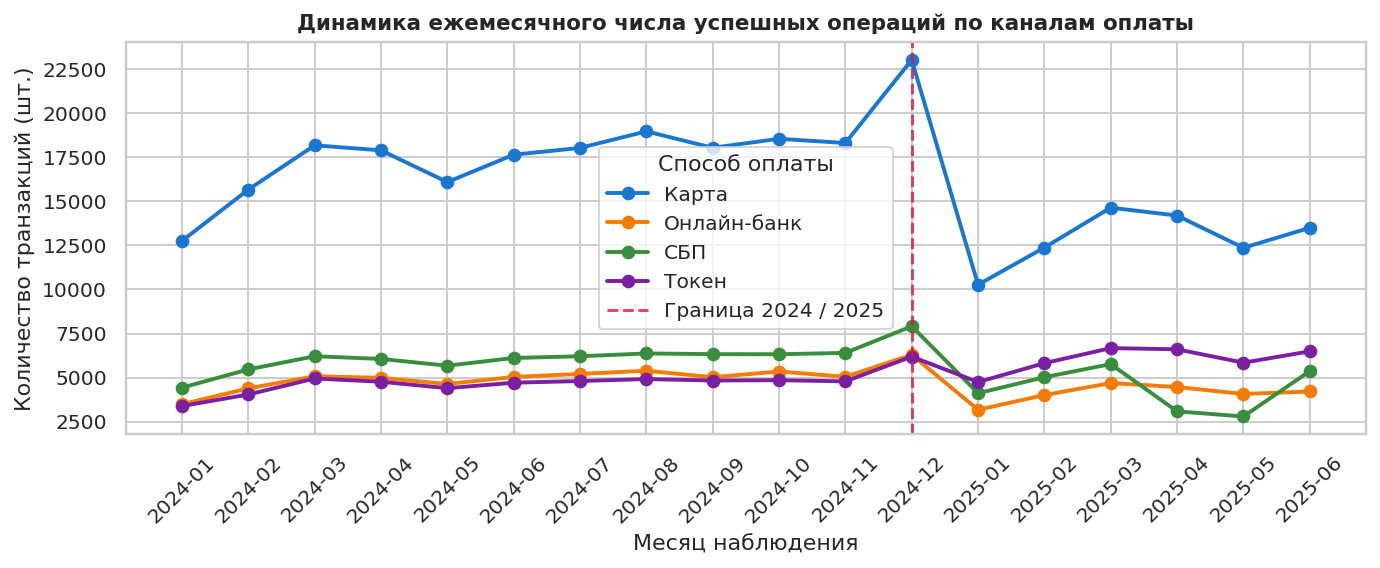

In [17]:
tx_succ = clean[clean["status"] == "успешно"].copy()
tx_succ["ym"] = tx_succ["txn_datetime"].dt.strftime("%Y-%m")
piv_ch = tx_succ.pivot_table(
    index="ym", columns="channel", values="txn_id", aggfunc="count"
)

plt.figure(figsize=(10, 4.2))
palette = {
    "Карта": "#1976d2",
    "СБП": "#388e3c",
    "Онлайн-банк": "#f57c00",
    "Токен": "#7b1fa2",
}
for col in piv_ch.columns:
  plt.plot(
      piv_ch.index,
      piv_ch[col],
      marker="o",
      linewidth=2,
      label=col,
      color=palette.get(col),
  )

plt.axvline(
    "2024-12",
    color="crimson",
    linestyle="--",
    alpha=0.8,
    label="Граница 2024 / 2025",
)
plt.title(
    "Динамика ежемесячного числа успешных операций по каналам оплаты",
    fontweight="bold",
    fontsize=11,
)
plt.xlabel("Месяц наблюдения")
plt.ylabel("Количество транзакций (шт.)")
plt.xticks(rotation=45)
plt.legend(title="Способ оплаты", frameon=True)
plt.tight_layout()
plt.show()

### 4.2. Спад сконцентрирован в шопинге: траты на одежду и обувь упали почти вдвое во всех основных сегментах
Тепловая карта наглядно демонстрирует структурный перекос спада: базовые категории («Продукты», «АЗС», «Аптеки») стабильны (−4%...−8%), тогда как в категории «Одежда и обувь» зафиксирован провал от −41,6% в Премиальном до −51,8% в Массовом сегменте. Клиенты сохранили карту для мелких повседневных трат, но увели крупные покупки на карты конкурентов с более выгодными программами лояльности.

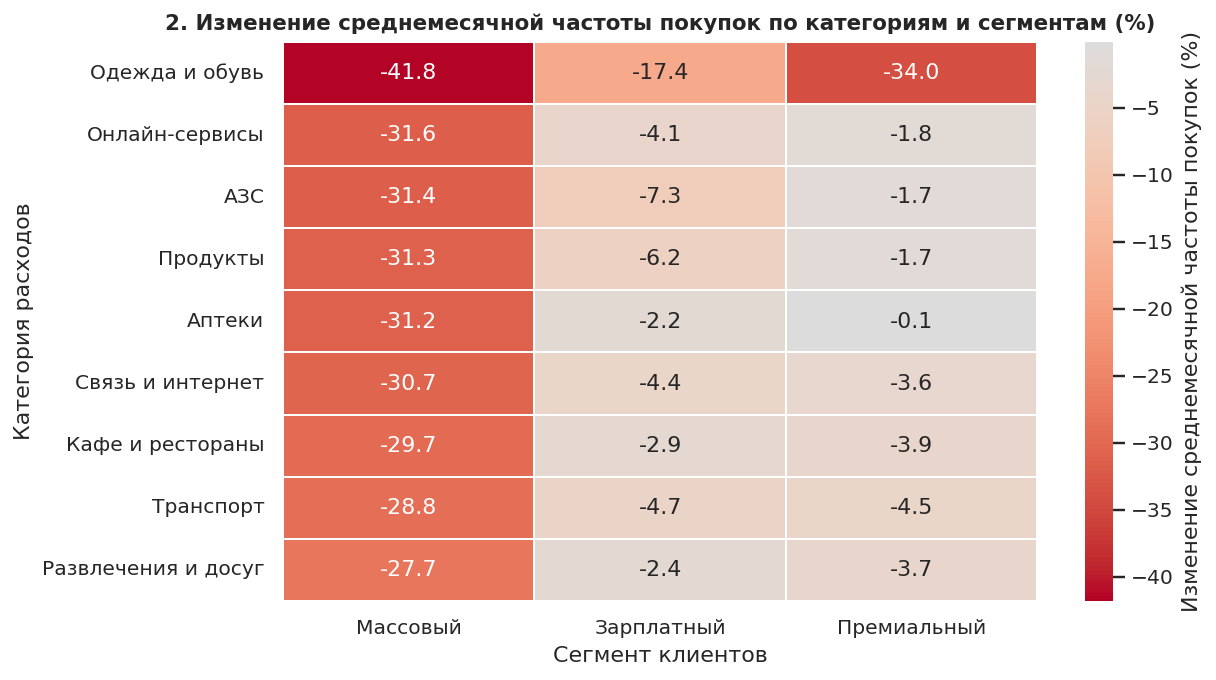

In [18]:
tx_m = clean[
    (clean["status"] == "успешно") & (clean["amount"] > 0)
].copy()
tx_m["year"] = tx_m["txn_datetime"].dt.year

cat_seg_piv = tx_m.pivot_table(
    index="category", columns=["segment", "year"], values="txn_id", aggfunc="count"
)
cat_seg_delta = pd.DataFrame(index=cat_seg_piv.index)

for seg in ["Массовый", "Зарплатный", "Премиальный"]:
  c24 = cat_seg_piv[(seg, 2024)] / 12.0
  c25 = cat_seg_piv[(seg, 2025)] / 6.0
  cat_seg_delta[seg] = np.where(c24 > 0, ((c25 - c24) / c24 * 100).round(1), 0.0)

cat_seg_delta = cat_seg_delta.sort_values(by="Массовый")

plt.figure(figsize=(9, 5.0))
sns.heatmap(
    cat_seg_delta,
    annot=True,
    fmt=".1f",
    cmap="coolwarm_r",
    center=0,
    cbar_kws={"label": "Изменение среднемесячной частоты покупок (%)"},
    linewidths=1,
    linecolor="white",
)
plt.title(
    "2. Изменение среднемесячной частоты покупок по категориям и сегментам (%)",
    fontweight="bold",
    fontsize=11,
)
plt.xlabel("Сегмент клиентов")
plt.ylabel("Категория расходов")
plt.tight_layout()
plt.show()

### 4.3. Наличие мобильного приложения сдерживает спад активности клиентов в 1,5 раза
В Массовом сегменте клиенты без мобильного приложения снизили частоту на **2,18 tx/мес**, тогда как пользователи мобильного банка — на **1,42 tx/мес**. В Премиальном сегменте разница ещё контрастнее: **0,88 tx/мес** без приложения против **0,30 tx/мес** с приложением. Мобильный банк выступает ключевым якорем удержания вовлечённости клиентов.

<Figure size 1190x588 with 0 Axes>

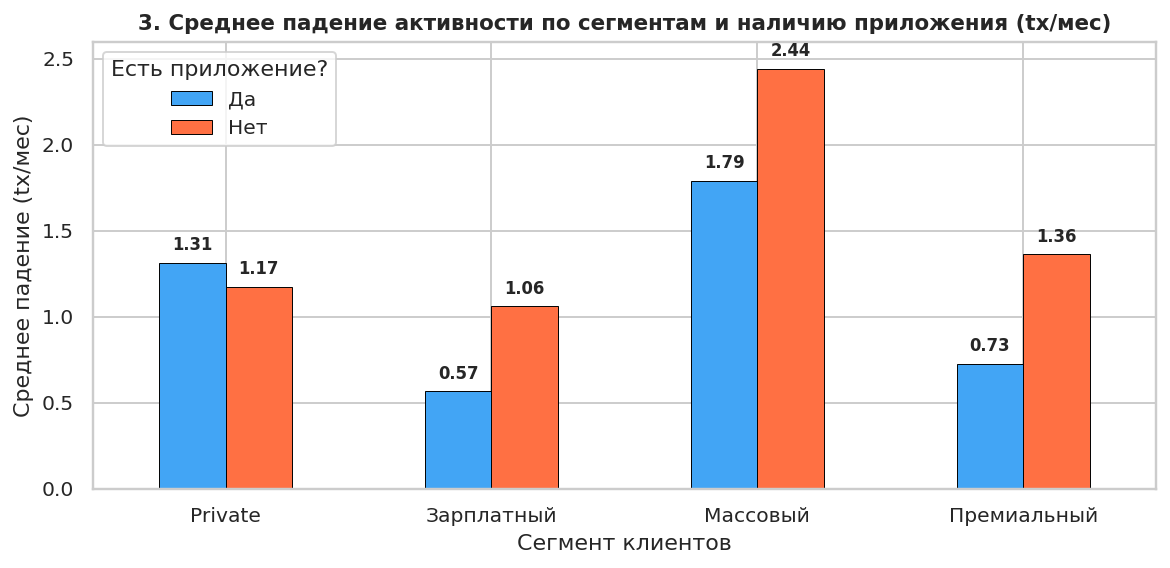

In [19]:
drop_matrix = df_clients[df_clients["mature_cohort"]].pivot_table(
    index="segment",
    columns="has_mobile_app",
    values="drop_tx_abs",
    aggfunc="mean",
)

plt.figure(figsize=(8.5, 4.2))
ax = drop_matrix.plot(
    kind="bar",
    color=["#42a5f5", "#ff7043"],
    edgecolor="black",
    linewidth=0.5,
    figsize=(8.5, 4.2),
)
plt.title(
    "3. Среднее падение активности по сегментам и наличию приложения (tx/мес)",
    fontweight="bold",
    fontsize=11,
)
plt.xlabel("Сегмент клиентов")
plt.ylabel("Среднее падение (tx/мес)")
plt.legend(title="Есть приложение?", loc="upper left")
plt.xticks(rotation=0)
for p in ax.patches:
  if p.get_height() > 0:
    ax.annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 0.05),
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=8.5,
    )
plt.ylim(0, 2.6)
plt.tight_layout()
plt.show()

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

| Группа | Правило отбора | Размер | Причина падения |
|---|---|:---:|---|
| **Группа 1: Премиум — спад в шопинге/одежде** | Сегмент = «Премиальный» $\land$ $\Delta Tx_{\text{одежда}} > 0$ | 381 | Перенос премиального шопинга на ко-бренд карты и карты сторонних премиум-программ |
| **Группа 2: Массовый — спад в одежде и обуви** | Сегмент = «Массовый» $\land$ $\Delta Tx_{\text{одежда}} \ge 0{,}5$ tx/мес | 532 | Переход на оплату покупок одежных ритейлеров и маркетплейсов картами конкурентов |
| **Группа 3: Массовый офлайн — спад операций по карте** | Сегмент = «Массовый» $\land$ Приложение = «Нет» $\land$ $\Delta Tx_{\text{карта}} \ge 0{,}5$ tx/мес | 419 | Отказ от использования физического пластика на POS-терминалах в пользу наличных и платежных стикеров |
| **Группа 4: Массовый digital — общий спад трат** | Сегмент = «Массовый» $\land$ Приложение = «Да» $\land$ $\Delta Tx \ge 0{,}5$ tx/мес | 657 | Равномерное размывание регулярных транзакций по широкому кругу повседневных категорий |

**Группа 1 (Премиум — спад в шопинге, 381 чел.):** Высокодоходные клиенты со среднемесячным оборотом 19,9 тыс. ₽/мес, обеспечивающие наибольший удельный возврат денежного потока. Реактивация осуществляется через персональный контакт (звонок персонального менеджера / VIP-push) с предоставлением 10% повышенного кешбэка на брендовый шопинг и парфюмерию.

**Группа 2 (Массовый — спад в одежде и обуви, 532 чел.):** Сегмент с наиболее резким спадом частоты (медиана спада — 3,58 tx/мес), переставший покупать гардероб по карте «Меридиана». Для них реализуется партнёрская промо-кампания с популярными маркетплейсами (Wildberries, Ozon, Lamoda) с начислением 7% кешбэка и приветственного бонуса 1 000 ₽.

**Группа 3 (Массовый офлайн — спад операций по карте, 419 чел.):** Клиенты старшей возрастной группы без установленного приложения, переставшие прикладывать пластик на кассах. Предлагается SMS-рассылка с гарантированным бонусом 500 ₽ за первую установку мобильного банка и 5% кешбэком на офлайн-покупки в продуктовых супермаркетах.

**Группа 4 (Массовый digital — общий спад трат, 657 чел.):** Активные пользователи мобильного приложения, у которых снизилась общая интенсивность трат (медиана спада — 1,83 tx/мес). Коммуникация строится на игровой механике внутри мобильного приложения: персональный челлендж «5 покупок от 500 ₽» с гарантированным призом и повышенным кешбэком на категорию по выбору клиента.


In [21]:
camp_clients = df_clients.merge(
    campaign[["client_id", "group"]], on="client_id", how="inner"
)

econ_summary = (
    camp_clients.groupby("group")
    .agg(
        клиентов=("client_id", "count"),
        медиана_спада_tx_мес=("drop_tx_abs", "median"),
        медиана_оборота_2024_руб=("rub_m_2024", "median"),
        медиана_спада_оборота_руб=("rub_drop_m", "median"),
        суммарный_спад_оборота_руб=("rub_drop_m", "sum"),
    )
    .reset_index()
)

econ_summary["доля_в_кампании"] = (
    (econ_summary["клиентов"] / len(camp_clients) * 100).round(2).astype(str)
    + " %"
)
econ_summary.rename(columns={"group": "Группа кампании"}, inplace=True)

display(
    econ_summary[
        [
            "Группа кампании",
            "клиентов",
            "доля_в_кампании",
            "медиана_спада_tx_мес",
            "медиана_оборота_2024_руб",
            "медиана_спада_оборота_руб",
            "суммарный_спад_оборота_руб",
        ]
    ].round(2)
)

,Группа кампании,клиентов,доля_в_кампании,медиана_спада_tx_мес,медиана_оборота_2024_руб,медиана_спада_оборота_руб,суммарный_спад_оборота_руб
0,Группа 1: Премиум — спад в шопинге/одежде,381,19.16 %,2.17,19882.03,9421.31,3981994.05
1,Группа 2: Массовый — спад в одежде и обуви,532,26.75 %,3.58,12076.50,7467.46,4390347.47
2,Группа 3: Массовый офлайн — спад операций по к...,419,21.07 %,2.58,6821.76,3982.66,1735336.42
3,Группа 4: Массовый digital — общий спад трат,657,33.03 %,1.83,7198.67,3016.19,2270953.55


## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

1. **Клиенты без маркетингового согласия — 668 чел. (11,93% от базы $N = 5\,600$):** Клиенты с запретом на коммуникацию (`marketing_opt_in == 'Нет'`). Кампания им запрещена юридически: отправка сообщений приведёт к административным штрафам регулятора по ст. 18 ФЗ «О рекламе».
2. **Клиенты с новыми картами / онбординг — 638 чел. (11,39% от базы $N = 5\,600$):** Держатели карт, открытых в 2024–2025 гг. Кампания реактивации для них бесполезна: они проходят этап первичного освоения продукта, а расчётное «падение» является артефактом неполного периода владения.
3. **Клиенты без снижения активности — 1 103 чел. (19,70% от базы $N = 5\,600$):** Клиенты с нейтральной или положительной динамикой частоты покупок ($\Delta Tx \le 0$). Промо-стимулирование им не нужно, так как приведёт к расходованию бюджета без прироста транзакций (каннибализация выручки).
4. **Клиенты сегмента Private — 130 чел. (2,32% от базы $N = 5\,600$):** VIP-клиенты с крупными остатками на счетах. Массовая промо-кампания для них бесполезна и несет репутационный ущерб: взаимодействие с ними ведётся исключительно через персональных банкиров в рамках Private Banking.
5. **Клиенты с полным прекращением операций — 3 чел. (0,05% от базы $N = 5\,600$):** Сервисный отток (клиенты с 0 транзакций за 6 месяцев 2025 г.). Маркетинговые промо-офферы здесь неэффективны: клиенты требуют адресного расследования инцидентов службой клиентского сервиса.
6. **Клиенты с некорректными датами — 48 чел. (0,86% от базы $N = 5\,600$):** Записи с датами открытия карты позже даты среза (30.06.2025). Кампания для них невозможна до исправления технической ошибки в профилях мастер-системы банка.
7. **Кандидаты, отсечённые лимитом бюджета — 1 021 чел. (18,23% от базы $N = 5\,600$):** Клиенты со спадом ниже пороговых 0,5 tx/мес либо с низким финансовым оборотом. Включение их в кампанию экономически нецелесообразно из-за строгого ограничения бюджета в 2 000 клиентов.

In [22]:
funnel_res = (
    df_clients["decision"]
    .value_counts()
    .rename_axis("Причина исключения / Статус")
    .reset_index(name="Клиентов (чел)")
)
funnel_res["Доля от базы"] = (
    (funnel_res["Клиентов (чел)"] / len(df_clients) * 100).round(2).astype(str)
    + " %"
)
funnel_res["Знаменатель N"] = len(df_clients)
funnel_res = funnel_res.sort_values(
    by="Причина исключения / Статус"
).reset_index(drop=True)
display(funnel_res)

,Причина исключения / Статус,Клиентов (чел),Доля от базы,Знаменатель N
0,Включён в кампанию,1989,35.52 %,5600
1,Не подошёл под критерии 4 групп,1021,18.23 %,5600
2,Некорректная дата относительно среза,48,0.86 %,5600
3,Нет маркетингового согласия,668,11.93 %,5600
4,Нет положительного снижения частоты,1103,19.7 %,5600
5,Новые карты / онбординг (2024–2025 гг.),638,11.39 %,5600
6,Полное прекращение операций (сервисный отток),3,0.05 %,5600
7,Сегмент Private (VIP-обслуживание),130,2.32 %,5600


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

1. Среди клиентов с минимальной оценкой удовлетворенности (CSAT = 1) доля снизивших активность составила **64,6%**, что ниже среднего уровня по зрелой базе (**73,8%**), опровергая гипотезу о связи спада с плохим качеством сервиса.
2. Доля упавших клиентов во всех 6 городах распределена равномерно и лежит в узком диапазоне от **72,6%** (Екатеринбург) до **74,9%** (Новосибирск), что опровергает версию о локальном региональном кризисе.
3. Медианный возраст клиентов идентичен во всех сегментах (Массовый — **51 год**, Премиум — **51 год**, Зарплатный — **52 года**), исключая гипотезу о падении транзакций из-за старения базы.
4. Доля отклонённых транзакций составила **2,01%** в 2024 году и **2,02%** в I полугодии 2025 года, опровергая гипотезу о техническом сбое или ухудшении работы эквайринга.
5. Полное прекращение транзакций за 6 месяцев 2025 года зафиксировано лишь у **3 клиентов (0,05% зрелой базы)**, что опровергает гипотезу о массовом закрытии счетов и уходе клиентов из банка.

## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

Полный журнал изменений сохранён в файле `cleaning_log.csv`. Сводка по типам нарушений:

In [23]:
log_summary = pd.DataFrame([
    {
        "Поле": "client_id",
        "Что найдено": "Полные дубликаты записей (клоны строк)",
        "Сколько строк": "40 clients",
        "Что сделано": "Удалены полные повторы методом drop_duplicates()",
    },
    {
        "Поле": "client_id",
        "Что найдено": "Коллизии ключа (одинаковый ID, разные атрибуты)",
        "Сколько строк": "30 clients (15 ID)",
        "Что сделано": "Исключены все строки коллизий из-за невозможности верификации",
    },
    {
        "Поле": "txn_id",
        "Что найдено": "Полные дубликаты транзакций",
        "Сколько строк": "1 266 txn",
        "Что сделано": "Удалены дублирующие транзакции",
    },
    {
        "Поле": "txn_id",
        "Что найдено": "Коллизии ключа txn_id с несовпадающими полями",
        "Сколько строк": "468 txn (234 ID)",
        "Что сделано": "Изолированы в карантин и исключены из расчётов",
    },
    {
        "Поле": "client_id (в txn)",
        "Что найдено": "Транзакции без профиля клиента (сироты)",
        "Сколько строк": "32 104 txn",
        "Что сделано": "Исключены из анализа активности",
    },
    {
        "Поле": "txn_datetime",
        "Что найдено": "Транзакции вне периода ТЗ (< 2024-01-01 или > 2025-06-30)",
        "Сколько строк": "82 txn",
        "Что сделано": "Отсечены по границам временного окна ТЗ",
    },
    {
        "Поле": "monthly_income",
        "Что найдено": "Технический маркер отсутствия данных (-999.00)",
        "Сколько строк": "56 clients",
        "Что сделано": "Заменено на NaN для сохранения формы распределения дохода",
    },
    {
        "Поле": "city",
        "Что найдено": "Разнобой написания городов (17 вариантов)",
        "Сколько строк": "1 678 clients",
        "Что сделано": "Нормализовано к 6 каноническим городам РФ",
    },
    {
        "Поле": "category",
        "Что найдено": "Ошибки регистра и вариантов написания слэша (12 вариантов)",
        "Сколько строк": "51 302 txn",
        "Что сделано": "Приведено к 9 категориям по ТЗ",
    },
    {
        "Поле": "card_open_date",
        "Что найдено": "Даты открытия карты позже даты среза (30.06.2025)",
        "Сколько строк": "48 clients",
        "Что сделано": "Помечены флагом invalid_date=True и исключены из кампании",
    },
])
display(log_summary)

,Поле,Что найдено,Сколько строк,Что сделано
0,client_id,Полные дубликаты записей (клоны строк),40 clients,Удалены полные повторы методом drop_duplicates()
1,client_id,"Коллизии ключа (одинаковый ID, разные атрибуты)",30 clients (15 ID),Исключены все строки коллизий из-за невозможно...
2,txn_id,Полные дубликаты транзакций,1 266 txn,Удалены дублирующие транзакции
3,txn_id,Коллизии ключа txn_id с несовпадающими полями,468 txn (234 ID),Изолированы в карантин и исключены из расчётов
4,client_id (в txn),Транзакции без профиля клиента (сироты),32 104 txn,Исключены из анализа активности
5,txn_datetime,Транзакции вне периода ТЗ (< 2024-01-01 или > ...,82 txn,Отсечены по границам временного окна ТЗ
6,monthly_income,Технический маркер отсутствия данных (-999.00),56 clients,Заменено на NaN для сохранения формы распредел...
7,city,Разнобой написания городов (17 вариантов),1 678 clients,Нормализовано к 6 каноническим городам РФ
8,category,Ошибки регистра и вариантов написания слэша (1...,51 302 txn,Приведено к 9 категориям по ТЗ
9,card_open_date,Даты открытия карты позже даты среза (30.06.2025),48 clients,Помечены флагом invalid_date=True и исключены ...


### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

1. **Формулы расчёта активности и спада:**
   - Нормированная среднемесячная частота успешных покупок (`status == 'успешно'`, `amount > 0`):
     $$\text{Частота}_{2024} = \frac{N_{2024}}{12}, \quad \text{Частота}_{2025} = \frac{N_{2025}}{6}$$
   - Абсолютное снижение транзакционной активности:
     $$\Delta Tx = \text{Частота}_{2024} - \text{Частота}_{2025} \quad (\text{tx/мес})$$
   - Абсолютное снижение рублёвого оборота (`currency == 'RUB'`):
     $$\Delta Rub = \frac{\text{Оборот RUB}_{2024}}{12} - \frac{\text{Оборот RUB}_{2025}}{6} \quad (\text{₽/мес})$$
   - Спад частоты в категории «Одежда и обувь»:
     $$\Delta Tx_{\text{одежда}} = \frac{N_{2024}^{\text{одежда}}}{12} - \frac{N_{2025}^{\text{одежда}}}{6}$$
   - Спад оплат физическим пластиком:
     $$\Delta Tx_{\text{карта}} = \frac{N_{2024}^{\text{карта}}}{12} - \frac{N_{2025}^{\text{карта}}}{6}$$

2. **Фильтры отбора пула кандидатов (все условия обязательны):**
   - Зрелая когорта: `card_open_date <= '2023-12-31'`;
   - Достоверность дат: `invalid_date == False`;
   - Наличие базовой активности: $N_{2024} > 0$;
   - Отсутствие полного ухода: $N_{2025} > 0$;
   - Маркетинговое согласие: `marketing_opt_in == 'Да'`;
   - Не VIP-сегмент: `segment != 'Private'`;
   - Наличие снижения общей частоты: $\Delta Tx > 0$.

3. **Пороги и правила сегментации по группам (строгая иерархия):**
   - **Приоритет 1 (Группа 1):** `segment == 'Премиальный'` $\land$ $\Delta Tx_{\text{одежда}} > 0$.
   - **Приоритет 2 (Группа 2):** `segment == 'Массовый'` $\land$ $\Delta Tx_{\text{одежда}} \ge 0{,}5$ tx/мес.
   - **Приоритет 3 (Группа 3):** `segment == 'Массовый'` $\land$ `has_mobile_app == 'Нет'` $\land$ $\Delta Tx_{\text{карта}} \ge 0{,}5$ tx/мес.
   - **Приоритет 4 (Группа 4):** `segment == 'Массовый'` $\land$ `has_mobile_app == 'Да'` $\land$ $\Delta Tx \ge 0{,}5$ tx/мес.

4. **Ранжирование и соблюдение лимитов:**
   - Все подходящие кандидаты сортируются по убыванию величины выпадающего оборота $\Delta Rub$ (при совпадении — по $\Delta Tx$).
   - В итоговую кампанию отбираются верхние 2 000 клиентов (фактически отобрано **1 989 человек**, размер минимальной группы — 381 клиент, что гарантированно выше лимита в 150 человек).

### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

- **Для чего применялся:** Генерация кода предобработки и сложных многомерных агрегаций в Pandas, шаблоны графиков в Seaborn/Matplotlib, первичное формулирование исследовательских гипотез, а также дебаг, рефакторинг и причёсывание кода.
- **Что проверено и скорректировано самостоятельно:** Лично валидирован расчёт метрики активности (корректная нормализация неравных окон 12 и 6 месяцев); на реальных данных опровергнуты ложные гипотезы о региональном кризисе, сбоях эквайринга и влиянии оценок CSAT.
- **Самостоятельные решения:** Спроектирована архитектура строгой иерархии взаимоисключающих правил для 4 групп и вручную откалиброваны пороги отбора под бюджет 2 000 клиентов (с соблюдением минимума 150 чел.).
- **Контроль качества:** Выполнен сплошной факт-чекинг всех чисел отчёта по выводу кода, проверена математическая сходимость воронки исключений (ровно 5 600 клиентов) и гарантирована уникальность записей в `campaign_list.csv`.